### Imports

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("..")

from query_history import query_history
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic
from sklearn.model_selection import LeaveOneOut, cross_val_score

### Data loading + appending with results from previous query

In [8]:
functions = {}

for i in range(1, 9):
    # Loading original data
    X = np.load(f"../initial_data/function_{i}/initial_inputs.npy")
    y = np.load(f"../initial_data/function_{i}/initial_outputs.npy")

    # Appending queries collected so far
    for query_X, query_y in query_history[i]:
        X = np.vstack([X, query_X])
        y = np.append(y, query_y)

    functions[i] = {
        "X": X,
        "y": y
    }

In [9]:
for i in range(1, 9):
    print(f"Function {i}: X = {functions[i]['X'].shape}, y = {functions[i]['y'].shape}")

Function 1: X = (11, 2), y = (11,)
Function 2: X = (11, 2), y = (11,)
Function 3: X = (16, 3), y = (16,)
Function 4: X = (31, 4), y = (31,)
Function 5: X = (21, 4), y = (21,)
Function 6: X = (21, 5), y = (21,)
Function 7: X = (31, 6), y = (31,)
Function 8: X = (41, 8), y = (41,)


### Reusable functions

In [41]:
def check_result(i):
    X, y = functions[i]["X"], functions[i]["y"]
    best = np.argmax(y)

    print(f"Function {i}")
    print(f"Latest: X={X[-1]}, y={y[-1]}")
    print(f"Best:   X={X[best]}, y={y[best]}")

In [42]:
def plot_2d(i, y=None):
    X = functions[i]["X"]
    y = functions[i]["y"] if y is None else y

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=80)
    plt.colorbar(label="Output")

    # Last week's query
    plt.scatter(X[-1, 0], X[-1, 1],
                marker="*", s=250, edgecolors="red",
                facecolors="none", linewidths=2,
                label="Last query")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}")
    plt.legend()
    plt.show()

In [63]:
kernels = {
    "RBF": RBF(0.1),
    "Matern": Matern(0.1, nu=2.5),
    "RQ": RationalQuadratic(length_scale=0.1, alpha=1.0)
}

length_scales = [0.05, 0.1, 0.2, 0.5]

def validate_kernels(i):
    X, y = functions[i]["X"], functions[i]["y"]
    results = {}

    for ls in length_scales:
        kernels = {
            "RBF": RBF(ls),
            "Matern": Matern(ls, nu=2.5),
            "RQ": RationalQuadratic(length_scale=ls, alpha=1.0)
        }

        for name, kernel in kernels.items():
            gp = GaussianProcessRegressor(
                kernel=kernel,
                normalize_y=True,
                optimizer=None
            )

            mae = -cross_val_score(
                gp, X, y,
                cv=LeaveOneOut(),
                scoring="neg_mean_absolute_error"
            ).mean()

            results[(name, ls)] = mae

    return sorted(results.items(), key=lambda x: x[1])

In [71]:
def fit_gp(i, kernel, transform=False):
    X, y = functions[i]["X"], functions[i]["y"]

    if transform:
        y = scale_scores(y)

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        optimizer=None
    )

    gp.fit(X, y)
    return gp

In [69]:
def plot_gp_2d(i, gp):
    X, y = functions[i]["X"], functions[i]["y"]

    grid = np.linspace(0, 1, 100)
    x1, x2 = np.meshgrid(grid, grid)
    X_grid = np.c_[x1.ravel(), x2.ravel()]

    mean, std = gp.predict(X_grid, return_std=True)

    plt.contourf(x1, x2, mean.reshape(x1.shape), levels=30)
    plt.colorbar(label="Predicted output")

    plt.scatter(X[:, 0], X[:, 1], c="white", edgecolors="black")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}: GP predicted mean")
    plt.show()

In [77]:
def acquisitions(gp, X_candidates, best_y, beta=1.96):
    mean, std = gp.predict(X_candidates, return_std=True)

    # UCB
    ucb = mean + beta * std

    # EI + PI
    improvement = mean - best_y
    z = improvement / (std + 1e-9)

    ei = improvement * norm.cdf(z) + std * norm.pdf(z)
    pi = norm.cdf(z)

    return {
        "UCB": X_candidates[np.argmax(ucb)],
        "EI":  X_candidates[np.argmax(ei)],
        "PI":  X_candidates[np.argmax(pi)]
    }

### Function 1

using transformations to make sense of the data

In [64]:
from sklearn.preprocessing import QuantileTransformer

def scale_scores(y):
    qt = QuantileTransformer(
        n_quantiles=len(y),
        output_distribution="uniform"
    )
    return qt.fit_transform(y.reshape(-1, 1)).ravel()

[0.5 0.8 1.  0.4 0.  0.2 0.3 0.9 0.5 0.7 0.1]


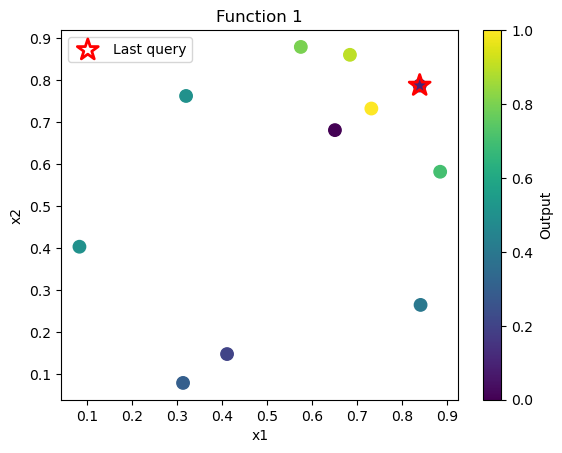

In [65]:
y_scaled = scale_scores(functions[1]["y"])

print(y_scaled)
plot_2d(1, y_scaled)

above i wanted to get a clearer visual picture of the promising region which seems to be approx (0.7, 0.8) - lets see if our new strategy agrees with this for the new query

In [66]:
validate_kernels(1)

[(('Matern', 0.05), np.float64(0.0006805348479151934)),
 (('RBF', 0.05), np.float64(0.0006846801600559985)),
 (('RQ', 0.05), np.float64(0.0007096467827269751)),
 (('Matern', 0.1), np.float64(0.0007326717601635349)),
 (('RQ', 0.1), np.float64(0.0008007521874227229)),
 (('RBF', 0.1), np.float64(0.0008387942257437522)),
 (('Matern', 0.2), np.float64(0.0010189123427982137)),
 (('RQ', 0.2), np.float64(0.0011625388955434923)),
 (('RBF', 0.2), np.float64(0.0013996939691102216)),
 (('Matern', 0.5), np.float64(0.001580467168858373)),
 (('RQ', 0.5), np.float64(0.0020516357148846346)),
 (('RBF', 0.5), np.float64(0.0036196004026023566))]

LOOCV showed that all three kernels performed best with a short length scale of 0.05, suggesting that F1 may vary substantially over small changes in input. Matérn 5/2 achieved the lowest MAE, although its performance was very close to RBF at the same length scale.

In [72]:
best_kernel = Matern(length_scale=0.05, nu=2.5)

gp_f1_scaled = fit_gp(
    1,
    best_kernel,
    transform=True
)

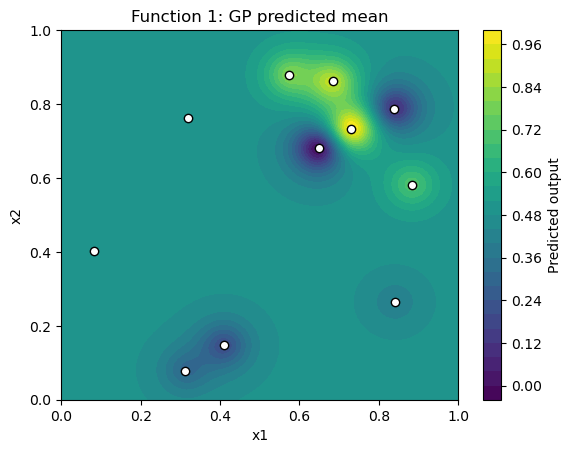

In [74]:
plot_gp_2d(1, gp_f1_scaled)

#### ucb, ei, pi

In [78]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(10000, 2)

In [79]:
suggestions = acquisitions(
    gp_f1_scaled,
    X_candidates,
    best_y=1.0
)

suggestions

{'UCB': array([0.72192397, 0.77351919]),
 'EI': array([0.72870925, 0.76121152]),
 'PI': array([0.7362376 , 0.73221756])}

all three acquisition functions suggest querying a similar region. this also aligns with my own observations, as F1 appears highly sensitive to small changes in the inputs, so exploiting the promising region around the current best point seems appropriate.